# Qwen3-4B-Base Ablation Study

This notebook measures **inference-time sensitivity** to transformer component ablations on two tasks:

- **POS tagging:** Universal Dependencies English Web Treebank (`en_ewt`), 5–20 annotated words per sentence. A linear probe is trained on baseline hidden states; Qwen itself remains frozen.
- **Sentiment classification:** IMDb `plain_text` test split, balanced positive/negative reviews with 20–250 whitespace-delimited words. For each review, the model compares the conditional likelihood of `positive` and `negative` continuations.

Ablations: bypass the **last N transformer blocks** (nested layer-removal schedule); zero selected query-head output slices; zero all token embeddings. The notebook produces CSV tables, plots, macro-F1/accuracy, and bootstrap confidence intervals.

**No fine-tuning or retraining of Qwen is performed.** The POS probe is a separate classifier trained over frozen hidden-state vectors, which is different from modifying Qwen's weights.

## Kaggle setup
1. In notebook **Settings**, enable **Internet** and select a **GPU accelerator**.
2. Run cells from the top. The model and datasets are public; the model and dataset IDs below are namespaced Hub IDs.
3. The lighter default uses **1,500 POS training sentences, 400 POS test sentences, and 300 balanced IMDb reviews** across **8 conditions**. Set `QUICK_RUN=True` in the configuration cell for a pipeline smoke test with much smaller subsets.
4. Results are checkpointed in `/kaggle/working`; rerunning the experiment cell resumes completed conditions for the same configuration.

Sources: [Qwen3-4B-Base model card](https://huggingface.co/Qwen/Qwen3-4B-Base), [Universal Dependencies Parquet dataset](https://huggingface.co/datasets/universal-dependencies/universal_dependencies), [IMDb](https://huggingface.co/datasets/stanfordnlp/imdb).

In [1]:
# Install before importing Transformers / Datasets. Keep Kaggle's installed torch.
%pip install -q "transformers>=4.51.0,<5.0" "datasets>=4.0.0,<5.0" "accelerate>=1.0.0" "scikit-learn>=1.4.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 68.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 63.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, gc, json, random, platform, warnings
from pathlib import Path
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, datasets, transformers, sklearn
from datasets import load_dataset
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MODEL_ID = "Qwen/Qwen3-4B-Base"
QUICK_RUN = False
if QUICK_RUN:
    # Pipeline-only smoke test; do not use these tiny results in the report.
    POS_TRAIN_SENTENCES, POS_TEST_SENTENCES, SENTIMENT_PER_CLASS = 400, 150, 40
else:
    # Lighter but still meaningful assignment run.
    POS_TRAIN_SENTENCES, POS_TEST_SENTENCES, SENTIMENT_PER_CLASS = 1500, 400, 150

POS_MIN_WORDS, POS_MAX_WORDS = 5, 20
SENT_MIN_WORDS, SENT_MAX_WORDS = 20, 250
POS_BATCH_SIZE = 4                 # lower memory use for hidden-state extraction
POS_MAX_SUBTOKENS = 128
SENTIMENT_BATCH_REVIEWS = 1        # 1 review -> 2 candidate strings per forward pass
MAX_SENTIMENT_TOKENS = 384         # shorter maximum context reduces inference cost
BOOTSTRAP_REPS = 300               
ABLATION_PLAN = [
    ("baseline", 0),
    ("layers", 3), ("layers", 9), ("layers", 18),
    ("heads", 8), ("heads", 16), ("heads", 32),
    ("embedding_zero", 0),
]

OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUTPUT_DIR / "qwen3_ablation_results.csv"
POS_DETAIL_CSV = OUTPUT_DIR / "qwen3_pos_predictions.csv"
SENT_DETAIL_CSV = OUTPUT_DIR / "qwen3_sentiment_predictions.csv"
CONFIG_JSON = OUTPUT_DIR / "qwen3_ablation_config.json"

print({"python": platform.python_version(), "torch": torch.__version__,
       "transformers": transformers.__version__, "datasets": datasets.__version__,
       "sklearn": sklearn.__version__, "CUDA": torch.cuda.is_available(),
       "output_dir": str(OUTPUT_DIR)})
if torch.cuda.is_available():
    print("GPU(s):", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'transformers': '4.57.6', 'datasets': '4.8.5', 'sklearn': '1.6.1', 'CUDA': True, 'output_dir': '/kaggle/working'}
GPU(s): ['Tesla T4', 'Tesla T4']


## 1. Load Qwen3-4B-Base

This checks for GPU availability before loading the 4B checkpoint. The model stays frozen; ablation hooks are applied temporarily during evaluation and removed afterwards.

In [3]:
if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU detected. In Kaggle Settings, enable a GPU accelerator and Internet, restart the session, then run all cells from the top.")

try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
    if not tokenizer.is_fast:
        raise RuntimeError("Fast tokenizer required for reliable word-to-subword POS alignment.")
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    model_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, torch_dtype=model_dtype, device_map="auto", low_cpu_mem_usage=True,
        attn_implementation="sdpa", use_safetensors=True,
    )
    model.eval()
    model.requires_grad_(False)
    model.config.use_cache = False
except Exception as exc:
    raise RuntimeError(
        "Could not load Qwen3-4B-Base. Confirm Kaggle Internet is enabled and the GPU accelerator is selected. "
        f"Original error: {type(exc).__name__}: {exc}"
    ) from exc

core = model.model
layers = core.layers
N_LAYERS = len(layers)
N_HEADS = int(model.config.num_attention_heads)
N_KV_HEADS = int(getattr(model.config, "num_key_value_heads", N_HEADS))
HIDDEN_SIZE = int(model.config.hidden_size)
HEAD_DIM = int(getattr(model.config, "head_dim", HIDDEN_SIZE // N_HEADS))
INPUT_DEVICE = model.get_input_embeddings().weight.device
# In Qwen3-4B-Base, hidden_size=2560 while 32 query heads x head_dim 128 = 4096.
# The concatenated attention heads feed o_proj, which maps 4096 -> 2560; these values
# are intentionally different. Validate head slicing against o_proj.in_features instead.
for li, layer in enumerate(layers):
    expected_attn_width = N_HEADS * HEAD_DIM
    if int(layer.self_attn.o_proj.in_features) != expected_attn_width:
        raise RuntimeError(
            f"Layer {li}: o_proj has {layer.self_attn.o_proj.in_features} input features, "
            f"but n_query_heads*head_dim={expected_attn_width}. Check Transformers/Qwen implementation."
        )
print({"layers": N_LAYERS, "query_heads": N_HEADS, "key_value_heads": N_KV_HEADS,
       "hidden_size": HIDDEN_SIZE, "head_dim": HEAD_DIM, "dtype": str(model_dtype),
       "input_device": str(INPUT_DEVICE), "device_map": getattr(model, "hf_device_map", None)})

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

...

model-00002-of-00003.safetensors:   0%|          | 0.00/3.99G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/99.6M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

{'layers': 36, 'query_heads': 32, 'key_value_heads': 8, 'hidden_size': 2560, 'head_dim': 128, 'dtype': 'torch.bfloat16', 'input_device': 'cuda:0', 'device_map': {'model.embed_tokens': 0, 'lm_head': 0, 'model.layers.0': 0, 'model.layers.1': 0, 'model.layers.2': 0, 'model.layers.3': 0, 'model.layers.4': 0, 'model.layers.5': 0, 'model.layers.6': 0, 'model.layers.7': 0, 'model.layers.8': 0, 'model.layers.9': 0, 'model.layers.10': 0, 'model.layers.11': 0, 'model.layers.12': 0, 'model.layers.13': 0, 'model.layers.14': 0, 'model.layers.15': 0, 'model.layers.16': 1, 'model.layers.17': 1, 'model.layers.18': 1, 'model.layers.19': 1, 'model.layers.20': 1, 'model.layers.21': 1, 'model.layers.22': 1, 'model.layers.23': 1, 'model.layers.24': 1, 'model.layers.25': 1, 'model.layers.26': 1, 'model.layers.27': 1, 'model.layers.28': 1, 'model.layers.29': 1, 'model.layers.30': 1, 'model.layers.31': 1, 'model.layers.32': 1, 'model.layers.33': 1, 'model.layers.34': 1, 'model.layers.35': 1, 'model.norm': 1, 

## 2. Load POS data: Universal Dependencies English EWT

Uses the current namespaced Parquet-backed UD repository, `en_ewt` configuration, and official train/test splits. Sentences are filtered to 5–20 annotated words.

In [4]:
try:
    ud = load_dataset("universal-dependencies/universal_dependencies", "en_ewt")
except Exception as exc:
    raise RuntimeError(
        "Could not load UD English EWT. Confirm Kaggle Internet is enabled. This notebook uses the "
        "namespaced ID 'universal-dependencies/universal_dependencies', not the legacy short ID. "
        f"Original error: {type(exc).__name__}: {exc}"
    ) from exc

print(ud)
print("Splits:", list(ud.keys()), "\nTrain columns:", ud["train"].column_names)
upos_feature = ud["train"].features.get("upos")
inner_upos_feature = upos_feature.feature if hasattr(upos_feature, "feature") else upos_feature
UPOS_NAMES = getattr(inner_upos_feature, "names", None)

def decode_upos(tag):
    if isinstance(tag, (int, np.integer)) and UPOS_NAMES is not None:
        i = int(tag)
        if 0 <= i < len(UPOS_NAMES):
            return str(UPOS_NAMES[i])
    return str(tag)

def normalize_ud_split(split):
    rows = []
    for ex in split:
        words, tags = ex.get("tokens"), ex.get("upos")
        if not words or not tags or len(words) != len(tags):
            continue
        if not (POS_MIN_WORDS <= len(words) <= POS_MAX_WORDS):
            continue
        if any(t is None or t == "_" for t in tags):
            continue
        rows.append({"tokens": list(words), "upos": [decode_upos(t) for t in tags]})
    return rows

if "train" not in ud or "test" not in ud:
    raise RuntimeError(f"Expected train and test splits; got {list(ud.keys())}")
train_pool, test_pool = normalize_ud_split(ud["train"]), normalize_ud_split(ud["test"])
if len(train_pool) < POS_TRAIN_SENTENCES or len(test_pool) < POS_TEST_SENTENCES:
    raise RuntimeError(f"Not enough length-filtered EWT sentences: train={len(train_pool)}, test={len(test_pool)}. Lower sample sizes or change the word range.")
rng = np.random.default_rng(SEED)
train_idx = rng.choice(len(train_pool), POS_TRAIN_SENTENCES, replace=False)
test_idx = rng.choice(len(test_pool), POS_TEST_SENTENCES, replace=False)
pos_train_rows = [train_pool[int(i)] for i in train_idx]
pos_test_rows = [test_pool[int(i)] for i in test_idx]
print(f"POS train: {len(pos_train_rows):,} sentences; POS test: {len(pos_test_rows):,} sentences")
print("Train sentence token min/max:", min(len(r["tokens"]) for r in pos_train_rows), max(len(r["tokens"]) for r in pos_train_rows))
print("Example:", " ".join(pos_train_rows[0]["tokens"]), pos_train_rows[0]["upos"])

README.md: 0.00B [00:00, ?B/s]

parquet/en_ewt/dev.parquet:   0%|          | 0.00/516k [00:00<?, ?B/s]

parquet/en_ewt/test.parquet:   0%|          | 0.00/523k [00:00<?, ?B/s]

parquet/en_ewt/train.parquet:   0%|          | 0.00/3.60M [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    dev: Dataset({
        features: ['sent_id', 'text', 'comments', 'tokens', 'lemmas', 'upos', 'xpos', 'feats', 'head', 'deprel', 'deps', 'misc', 'mwt', 'empty_nodes'],
        num_rows: 2001
    })
    test: Dataset({
        features: ['sent_id', 'text', 'comments', 'tokens', 'lemmas', 'upos', 'xpos', 'feats', 'head', 'deprel', 'deps', 'misc', 'mwt', 'empty_nodes'],
        num_rows: 2077
    })
    train: Dataset({
        features: ['sent_id', 'text', 'comments', 'tokens', 'lemmas', 'upos', 'xpos', 'feats', 'head', 'deprel', 'deps', 'misc', 'mwt', 'empty_nodes'],
        num_rows: 12544
    })
})
Splits: ['dev', 'test', 'train'] 
Train columns: ['sent_id', 'text', 'comments', 'tokens', 'lemmas', 'upos', 'xpos', 'feats', 'head', 'deprel', 'deps', 'misc', 'mwt', 'empty_nodes']
POS train: 1,500 sentences; POS test: 400 sentences
Train sentence token min/max: 5 20
Example: Make sure the temperature is good . ['VERB', 'ADJ', 'DET', 'NOUN', 'AUX', 'ADJ', 'PUNCT']


## 3. Load sentiment data: IMDb reviews

Uses `stanfordnlp/imdb`, configuration `plain_text`, and its official test split. We sample equally from both labels after filtering to 20–250 whitespace-delimited words. This is review-level sentiment, not a sentence-level sentiment benchmark.

In [5]:
try:
    imdb = load_dataset("stanfordnlp/imdb", "plain_text")
except Exception as exc:
    raise RuntimeError(
        "Could not load IMDb. This notebook uses 'stanfordnlp/imdb' with the 'plain_text' configuration. "
        "Confirm Kaggle Internet is enabled. " f"Original error: {type(exc).__name__}: {exc}"
    ) from exc
print(imdb)
if "test" not in imdb:
    raise RuntimeError(f"Expected IMDb test split; found {list(imdb.keys())}")

def word_count(text):
    return len(str(text).split())

sent_pool = []
for ex in imdb["test"]:
    text = str(ex.get("text", "")).strip()
    label = ex.get("label")
    if not text or label is None:
        continue
    label, wc = int(label), word_count(text)
    if label in (0, 1) and SENT_MIN_WORDS <= wc <= SENT_MAX_WORDS:
        sent_pool.append({"text": text, "label": label, "words": wc})
negative = [r for r in sent_pool if r["label"] == 0]
positive = [r for r in sent_pool if r["label"] == 1]
need = SENTIMENT_PER_CLASS
if min(len(negative), len(positive)) < need:
    raise RuntimeError(f"Filtered IMDb pool is too small: neg={len(negative)}, pos={len(positive)}, need={need}/class. Lower sample size or broaden word range.")
rng = np.random.default_rng(SEED + 1)
ni = rng.choice(len(negative), need, replace=False)
pi = rng.choice(len(positive), need, replace=False)
sentiment_rows = [negative[int(i)] for i in ni] + [positive[int(i)] for i in pi]
rng.shuffle(sentiment_rows)
sentiment_df = pd.DataFrame(sentiment_rows)
sentiment_df["length_bucket"] = pd.cut(sentiment_df["words"], bins=[19, 60, 120, 250], labels=["20–60", "61–120", "121–250"], include_lowest=True)
display(sentiment_df.groupby(["label", "length_bucket"], observed=False).size().unstack(fill_value=0))
print("Balanced sentiment reviews:", len(sentiment_rows))
display(sentiment_df[["label", "words", "text"]].head(2))

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

...

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


length_bucket,20–60,61–120,121–250
label,,,
0,5,27,118
1,6,30,114


Balanced sentiment reviews: 300


,label,words,text
0,1,132,"NVA combines eastalgia-humor, military comedy ..."
1,0,137,The few scenes that actually attempt a depicti...


## 4. Ablation hooks

- **Layer bypass:** bypass the **final N transformer blocks** (3, 9, then 18), so each larger condition includes the previous one. This makes the layer-ablation schedule nested and easier to interpret as increasing removal of late-stage transformations.
- **Attention-head ablation:** zero selected query-head output slices before the attention output projection. Head subsets are deterministic and nested across amounts (8, 16, then 32 heads per layer).
- **Embedding ablation:** zero all token embedding outputs.

All hooks are removed after each forward evaluation. These are inference-time interventions, not parameter removal followed by retraining.

**Qwen3 dimension note:** hidden size is 2,560, but attention head width is 32 × 128 = 4,096 before the output projection. Head ablation therefore slices the 4,096-dimensional projection input, not the residual hidden state.

In [6]:
def choose_layer_indices(n):
    """Bypass the final n blocks, giving nested progressive conditions.

    Example for a 36-layer checkpoint: n=3 -> [33, 34, 35];
    n=9 contains those same three plus the preceding six blocks.
    """
    n = min(max(int(n), 0), N_LAYERS)
    return list(range(N_LAYERS - n, N_LAYERS))

def head_indices_by_layer(n):
    result = {}
    for li in range(N_LAYERS):
        order = np.random.default_rng(SEED + 1009 * (li + 1)).permutation(N_HEADS)
        result[li] = [int(v) for v in order[:min(int(n), N_HEADS)]]
    return result

@contextmanager
def apply_ablation(kind="baseline", amount=0):
    handles = []
    try:
        if kind == "baseline":
            pass
        elif kind == "layers":
            for li in choose_layer_indices(amount):
                def bypass(module, inputs, output):
                    if isinstance(output, tuple):
                        return (inputs[0],) + output[1:]
                    return inputs[0]
                handles.append(layers[li].register_forward_hook(bypass))
        elif kind == "heads":
            selected_by_layer = head_indices_by_layer(amount)
            for li, layer in enumerate(layers):
                proj = layer.self_attn.o_proj
                if int(proj.in_features) != N_HEADS * HEAD_DIM:
                    raise RuntimeError(f"Layer {li}: o_proj input size {proj.in_features} differs from {N_HEADS}*{HEAD_DIM}; check Transformers version.")
                selected = selected_by_layer[li]
                def zero_heads(module, inputs, selected=selected):
                    x = inputs[0].clone()
                    for h in selected:
                        x[..., h * HEAD_DIM:(h + 1) * HEAD_DIM] = 0
                    return (x,) + tuple(inputs[1:])
                handles.append(proj.register_forward_pre_hook(zero_heads))
        elif kind == "embedding_zero":
            def zero_emb(module, inputs, output):
                return torch.zeros_like(output)
            handles.append(model.get_input_embeddings().register_forward_hook(zero_emb))
        else:
            raise ValueError(f"Unknown ablation: {kind}")
        yield
    finally:
        for handle in handles:
            handle.remove()

print("Architecture:", N_LAYERS, "layers;", N_HEADS, "query heads/layer;", N_KV_HEADS, "KV heads/layer")
print("Nested last-N layer indices:", {n: choose_layer_indices(n) for n in [3, 9, 18]})

Architecture: 36 layers; 32 query heads/layer; 8 KV heads/layer
Nested last-N layer indices: {3: [33, 34, 35], 9: [27, 28, 29, 30, 31, 32, 33, 34, 35], 18: [18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35]}


## 5. Smoke test the model and intervention hooks

A short forward pass under each intervention type catches compatibility problems before the longer evaluation begins.

In [7]:
test = tokenizer("The quick brown fox jumps over the lazy dog.", return_tensors="pt")
test = {k: v.to(INPUT_DEVICE) for k, v in test.items()}
for kind, amount in [("baseline", 0), ("layers", 1), ("heads", 1), ("embedding_zero", 0)]:
    with apply_ablation(kind, amount), torch.inference_mode():
        out = model(**test, use_cache=False)
        assert out.logits.ndim == 3 and torch.isfinite(out.logits[:, -1, :]).all().item()
        print(f"{kind}={amount}: logits {tuple(out.logits.shape)}, finite=True")
del test, out
gc.collect(); torch.cuda.empty_cache()
print("Hook smoke test passed.")

baseline=0: logits (1, 10, 151936), finite=True
layers=1: logits (1, 10, 151936), finite=True
heads=1: logits (1, 10, 151936), finite=True
embedding_zero=0: logits (1, 10, 151936), finite=True
Hook smoke test passed.


## 6. POS hidden-state features and fixed linear probe

`is_split_into_words=True` enables reliable alignment between UD word labels and subword pieces. The first subword's final hidden vector represents each annotated word. The same probe, trained on baseline vectors, is evaluated on every ablated condition. This measures whether the original readout survives the intervention; it does not fine-tune Qwen.

In [8]:
def extract_pos_features(rows, kind="baseline", amount=0, batch_size=POS_BATCH_SIZE):
    chunks, all_tags, all_groups = [], [], []
    total_words = aligned = 0
    with apply_ablation(kind, amount), torch.inference_mode():
        for start in tqdm(range(0, len(rows), batch_size), desc=f"POS {kind}={amount}"):
            batch = rows[start:start + batch_size]
            enc = tokenizer([r["tokens"] for r in batch], is_split_into_words=True,
                            return_tensors="pt", padding=True, truncation=True,
                            max_length=POS_MAX_SUBTOKENS, add_special_tokens=True)
            ids = enc["input_ids"].to(INPUT_DEVICE)
            mask = enc["attention_mask"].to(INPUT_DEVICE)
            out = model.model(input_ids=ids, attention_mask=mask, use_cache=False, return_dict=True)
            hidden = out.last_hidden_state.float().cpu().numpy()
            bx, by, bg = [], [], []
            for b, row in enumerate(batch):
                word_ids = enc.word_ids(batch_index=b)
                first_subword = {}
                for ti, wi in enumerate(word_ids):
                    if wi is not None and wi not in first_subword:
                        first_subword[wi] = ti
                total_words += len(row["tokens"])
                local_x, local_y = [], []
                for wi, tag in enumerate(row["upos"]):
                    ti = first_subword.get(wi)
                    if ti is not None:
                        local_x.append(hidden[b, ti]); local_y.append(tag)
                bx.extend(local_x); by.extend(local_y); bg.extend([start + b] * len(local_y))
                aligned += len(local_y)
            if bx:
                chunks.append(np.asarray(bx, dtype=np.float32))
                all_tags.extend(by); all_groups.extend(bg)
            del out, hidden, ids, mask, enc
    if not chunks:
        raise RuntimeError("No POS vectors extracted. Check the dataset schema and fast tokenizer alignment.")
    X = np.concatenate(chunks, axis=0)
    y = np.asarray(all_tags, dtype=object)
    groups = np.asarray(all_groups, dtype=np.int32)
    del chunks
    print(f"Word alignment: {aligned:,}/{total_words:,} ({aligned/max(total_words,1):.1%})")
    return X, y, groups

X_pos_train, y_pos_train, _ = extract_pos_features(pos_train_rows)
X_test_all, y_test_all, groups_test_all = extract_pos_features(pos_test_rows)
known_tags = set(y_pos_train.tolist())
known_mask = np.asarray([y in known_tags for y in y_test_all], dtype=bool)
POS_TEST_COVERAGE = float(known_mask.mean())
X_pos_test = X_test_all[known_mask].copy()
y_pos_test = y_test_all[known_mask]
groups_pos_test = groups_test_all[known_mask]
del X_test_all, y_test_all, groups_test_all, known_mask
gc.collect()
print(f"Evaluation coverage after excluding unseen training labels: {POS_TEST_COVERAGE:.1%}")
print("Feature shapes:", X_pos_train.shape, X_pos_test.shape)

POS baseline=0:   0%|          | 0/375 [00:00<?, ?it/s]

Word alignment: 18,484/18,484 (100.0%)


POS baseline=0:   0%|          | 0/100 [00:00<?, ?it/s]

Word alignment: 4,306/4,306 (100.0%)
Evaluation coverage after excluding unseen training labels: 100.0%
Feature shapes: (18484, 2560) (4306, 2560)


In [9]:
# Scaled SGD logistic probe avoids the LBFGS non-convergence issue on large hidden-state matrices.
pos_probe = make_pipeline(
    StandardScaler(with_mean=False),
    SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=2000, tol=1e-3,
                  early_stopping=True, validation_fraction=0.1,
                  n_iter_no_change=8, random_state=SEED),
)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    pos_probe.fit(X_pos_train, y_pos_train)
del X_pos_train, y_pos_train
gc.collect()
print("Probe epochs:", pos_probe.named_steps["sgdclassifier"].n_iter_)
for warning in caught: print("Probe warning:", warning.message)
pos_baseline_pred = pos_probe.predict(X_pos_test)
print("Baseline POS accuracy:", round(accuracy_score(y_pos_test, pos_baseline_pred), 4))
print("Baseline POS macro-F1:", round(f1_score(y_pos_test, pos_baseline_pred, average="macro", zero_division=0), 4))
print(classification_report(y_pos_test, pos_baseline_pred, zero_division=0))

Probe epochs: 23
Baseline POS accuracy: 0.8474
Baseline POS macro-F1: 0.7844
              precision    recall  f1-score   support

         ADJ       0.69      0.78      0.73       285
         ADP       0.83      0.93      0.87       340
         ADV       0.66      0.65      0.66       214
         AUX       0.97      0.80      0.88       333
       CCONJ       0.94      0.99      0.97       102
         DET       0.90      0.92      0.91       314
        INTJ       0.88      0.71      0.79        21
        NOUN       0.82      0.78      0.80       677
         NUM       0.90      0.87      0.89        85
        PART       0.93      0.92      0.92       122
        PRON       0.92      0.94      0.93       453
       PROPN       0.81      0.66      0.72       285
       PUNCT       0.98      0.99      0.99       521
       SCONJ       0.78      0.60      0.67        52
         SYM       0.95      0.69      0.80        26
        VERB       0.76      0.85      0.80       475
    

## 7. Tokenize IMDb review continuations once

The base LM is not assumed to follow chat-style instructions. It scores the candidate continuations `positive` and `negative` after a fixed `Review: … Sentiment:` prefix. Candidate token IDs are precomputed once and reused across all ablations. The review is token-capped to preserve space for the label, while all source reviews first pass the requested 20–250 word filter.

In [10]:
def prepare_sentiment(rows):
    """Tokenize each review once; mark only label continuation tokens for scoring.

    Character offsets are used instead of comparing prefix tokenizations, because BPE
    tokenization at the prompt/continuation boundary can change when text is appended.
    """
    prepared = []
    for row in tqdm(rows, desc="Tokenizing IMDb candidates"):
        review_ids = tokenizer(
            str(row["text"]), add_special_tokens=False,
            truncation=True, max_length=MAX_SENTIMENT_TOKENS - 64
        )["input_ids"]
        review = tokenizer.decode(review_ids, skip_special_tokens=True)
        prefix = f"Review:\n{review}\n\nSentiment:"
        candidate_ids, target_positions = [], []
        for label in ("positive", "negative"):
            full_text = prefix + " " + label
            enc = tokenizer(
                full_text, add_special_tokens=True,
                max_length=MAX_SENTIMENT_TOKENS, truncation=True,
                return_offsets_mapping=True,
            )
            ids = [int(x) for x in enc["input_ids"]]
            offsets = enc["offset_mapping"]
            # Continuation tokens have character spans extending beyond the prefix.
            target = [
                i for i, (char_start, char_end) in enumerate(offsets)
                if char_end > len(prefix) and char_end > char_start and i >= 1
            ]
            if not target:
                raise RuntimeError(
                    f"No continuation tokens found for label {label!r}; "
                    "check the tokenizer's offset_mapping behavior."
                )
            candidate_ids.append(ids)
            target_positions.append(target)
        prepared.append({
            "label": int(row["label"]),
            "words": int(row["words"]),
            "length_bucket": "20–60" if row["words"] <= 60 else ("61–120" if row["words"] <= 120 else "121–250"),
            "candidate_ids": candidate_ids,
            "target_positions": target_positions,
        })
    return prepared

prepared_sentiment = prepare_sentiment(sentiment_rows)
print("Tokenized reviews:", len(prepared_sentiment))
print("Example candidate lengths:", [len(x) for x in prepared_sentiment[0]["candidate_ids"]])
print("Example scored label token positions:", prepared_sentiment[0]["target_positions"])


Tokenizing IMDb candidates:   0%|          | 0/300 [00:00<?, ?it/s]

Tokenized reviews: 300
Example candidate lengths: [179, 179]
Example scored label token positions: [[178], [178]]


## 8. Sentiment scoring function and smoke test

Only the logits needed to score the continuation tokens are converted to float32. The full vocabulary dimension is retained only for those few positions, reducing GPU-memory use.

In [11]:
def score_candidate_batch(batch, kind, amount):
    # Two sequences per review: candidate label 0=positive, 1=negative.
    flat_ids, owner, sign, targets_by_seq = [], [], [], []
    for j, entry in enumerate(batch):
        for s in (0, 1):
            flat_ids.append(entry["candidate_ids"][s])
            owner.append(j)
            sign.append(s)
            targets_by_seq.append(entry["target_positions"][s])

    max_len = max(map(len, flat_ids))
    pad = int(tokenizer.pad_token_id)
    input_ids = torch.full((len(flat_ids), max_len), pad, dtype=torch.long)
    attention_mask = torch.zeros((len(flat_ids), max_len), dtype=torch.long)
    for i, ids in enumerate(flat_ids):
        input_ids[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
        attention_mask[i, :len(ids)] = 1
    input_ids = input_ids.to(INPUT_DEVICE)
    attention_mask = attention_mask.to(INPUT_DEVICE)
    scores = [[None, None] for _ in batch]

    with apply_ablation(kind, amount), torch.inference_mode():
        out = model(input_ids=input_ids, attention_mask=attention_mask, use_cache=False)
        logits = out.logits
        for i, ids in enumerate(flat_ids):
            # Token t is predicted by logits at position t-1. Only continuation tokens are scored.
            target_pos = targets_by_seq[i]
            pred_pos = torch.tensor([t - 1 for t in target_pos], dtype=torch.long, device=logits.device)
            targets = torch.tensor([ids[t] for t in target_pos], dtype=torch.long, device=logits.device)
            selected = logits[i, pred_pos, :].float()
            token_lp = selected.gather(1, targets[:, None]).squeeze(1) - torch.logsumexp(selected, dim=-1)
            scores[owner[i]][sign[i]] = float(token_lp.mean().item())
    del out, logits, input_ids, attention_mask
    return scores

def score_sentiment(entries, kind, amount, batch_reviews=SENTIMENT_BATCH_REVIEWS):
    preds, pair_scores = [], []
    gold = np.asarray([e["label"] for e in entries], dtype=np.int64)
    for start in tqdm(range(0, len(entries), batch_reviews), desc=f"IMDb {kind}={amount}"):
        batch = entries[start:start + batch_reviews]
        try:
            local = score_candidate_batch(batch, kind, amount)
        except RuntimeError as exc:
            if "out of memory" not in str(exc).lower() or len(batch) == 1:
                raise
            torch.cuda.empty_cache()
            local = []
            for entry in batch:
                local.extend(score_candidate_batch([entry], kind, amount))
        for pscore, nscore in local:
            pair_scores.append((pscore, nscore))
            preds.append(1 if pscore > nscore else 0)
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    preds = np.asarray(preds, dtype=np.int64)
    return {"accuracy": float(accuracy_score(gold, preds)),
            "macro_f1": float(f1_score(gold, preds, average="macro", zero_division=0)),
            "predictions": preds, "scores": pair_scores, "gold": gold}

smoke = score_sentiment(prepared_sentiment[:2], "baseline", 0, batch_reviews=2)
print("Two-review smoke test accuracy:", smoke["accuracy"])


IMDb baseline=0:   0%|          | 0/1 [00:00<?, ?it/s]

Two-review smoke test accuracy: 1.0


## 9. Run ablations (with checkpoints)

Each condition evaluates both tasks on the same samples. The POS probe is fixed across conditions. Results are saved after each completed condition. If execution stops, rerun this cell to resume. If you edit sample sizes, random seed or ablation schedule, the configuration check clears stale result CSVs.

In [12]:
run_config = {"model_id": MODEL_ID, "quick_run": QUICK_RUN,
              "pos_train_sentences": POS_TRAIN_SENTENCES, "pos_test_sentences": POS_TEST_SENTENCES,
              "sentiment_per_class": SENTIMENT_PER_CLASS,
              "pos_word_range": [POS_MIN_WORDS, POS_MAX_WORDS],
              "sentiment_word_range": [SENT_MIN_WORDS, SENT_MAX_WORDS],
              # JSON converts tuples to lists; normalize now so unchanged runs resume correctly.
              "ablation_plan": [[kind, int(amount)] for kind, amount in ABLATION_PLAN],
              "layer_ablation_strategy": "last_n_layers",
              "pos_batch_size": POS_BATCH_SIZE,
              "max_sentiment_tokens": MAX_SENTIMENT_TOKENS,
              "sentiment_batch_reviews": SENTIMENT_BATCH_REVIEWS,
              "bootstrap_reps": BOOTSTRAP_REPS,
              "seed": SEED,
              "transformers": transformers.__version__, "datasets": datasets.__version__}
if CONFIG_JSON.exists():
    old_config = json.loads(CONFIG_JSON.read_text())
    if old_config != run_config:
        print("Configuration changed; clearing old CSV checkpoints.")
        for p in (RESULTS_CSV, POS_DETAIL_CSV, SENT_DETAIL_CSV):
            if p.exists(): p.unlink()
else:
    # Avoid accidentally reusing orphaned outputs from a prior notebook/config.
    for p in (RESULTS_CSV, POS_DETAIL_CSV, SENT_DETAIL_CSV):
        if p.exists(): p.unlink()
CONFIG_JSON.write_text(json.dumps(run_config, indent=2))

results = pd.read_csv(RESULTS_CSV).to_dict("records") if RESULTS_CSV.exists() else []
pos_cols = ["condition", "sentence_id", "gold", "predicted"]
sent_cols = ["condition", "review_id", "gold", "predicted", "words", "length_bucket", "positive_mean_logprob", "negative_mean_logprob"]
pos_details = pd.read_csv(POS_DETAIL_CSV) if POS_DETAIL_CSV.exists() else pd.DataFrame(columns=pos_cols)
sent_details = pd.read_csv(SENT_DETAIL_CSV) if SENT_DETAIL_CSV.exists() else pd.DataFrame(columns=sent_cols)
completed = {str(r["condition"]) for r in results}

for kind, amount in ABLATION_PLAN:
    condition = f"{kind}_{amount}"
    if condition in completed:
        print("Skipping completed:", condition); continue
    print("\n" + "=" * 60 + "\nCondition: " + condition + "\n" + "=" * 60)

    if kind == "baseline":
        X_eval, y_eval, group_eval = X_pos_test, y_pos_test, groups_pos_test
    else:
        X_all, y_all, g_all = extract_pos_features(pos_test_rows, kind, amount)
        mask = np.asarray([tag in known_tags for tag in y_all], dtype=bool)
        X_eval, y_eval, group_eval = X_all[mask], y_all[mask], g_all[mask]
        del X_all, y_all, g_all
    pos_pred = pos_probe.predict(X_eval)
    pos_acc = float(accuracy_score(y_eval, pos_pred))
    pos_f1 = float(f1_score(y_eval, pos_pred, average="macro", zero_division=0))
    # Replace condition rows if a prior attempt wrote details but not the summary checkpoint.
    pos_details = pos_details[pos_details["condition"] != condition]
    sent_details = sent_details[sent_details["condition"] != condition]
    pos_details = pd.concat([pos_details, pd.DataFrame({
        "condition": condition, "sentence_id": group_eval.astype(int),
        "gold": y_eval.astype(str), "predicted": pos_pred.astype(str)})], ignore_index=True)
    del X_eval; gc.collect()

    sent_out = score_sentiment(prepared_sentiment, kind, amount)
    sent_acc, sent_f1 = sent_out["accuracy"], sent_out["macro_f1"]
    sent_details = pd.concat([sent_details, pd.DataFrame({
        "condition": condition, "review_id": np.arange(len(sentiment_rows)),
        "gold": sent_out["gold"], "predicted": sent_out["predictions"],
        "words": [e["words"] for e in prepared_sentiment],
        "length_bucket": [e["length_bucket"] for e in prepared_sentiment],
        "positive_mean_logprob": [s[0] for s in sent_out["scores"]],
        "negative_mean_logprob": [s[1] for s in sent_out["scores"]]})], ignore_index=True)

    row = {"condition": condition, "ablation": kind, "amount": int(amount),
           "layers_bypassed": len(choose_layer_indices(amount)) if kind == "layers" else 0,
           "heads_zeroed_per_layer": int(amount) if kind == "heads" else 0,
           "pos_accuracy": pos_acc, "pos_macro_f1": pos_f1,
           "sentiment_accuracy": sent_acc, "sentiment_macro_f1": sent_f1}
    results.append(row)
    # Write detail first, then summary as the completion marker.
    pos_details.to_csv(POS_DETAIL_CSV, index=False)
    sent_details.to_csv(SENT_DETAIL_CSV, index=False)
    pd.DataFrame(results).to_csv(RESULTS_CSV, index=False)
    completed.add(condition)
    print(row)

results_df = pd.DataFrame(results)
display(results_df.sort_values(["ablation", "amount"]).round(4))
print("Results:", RESULTS_CSV, "\nPOS details:", POS_DETAIL_CSV, "\nSentiment details:", SENT_DETAIL_CSV)


Condition: baseline_0


IMDb baseline=0:   0%|          | 0/300 [00:00<?, ?it/s]

{'condition': 'baseline_0', 'ablation': 'baseline', 'amount': 0, 'layers_bypassed': 0, 'heads_zeroed_per_layer': 0, 'pos_accuracy': 0.8474222015791918, 'pos_macro_f1': 0.7843563734389517, 'sentiment_accuracy': 0.7066666666666667, 'sentiment_macro_f1': 0.6944444444444444}

Condition: layers_3


/tmp/ipykernel_23/3701769097.py:60: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  sent_details = pd.concat([sent_details, pd.DataFrame({


POS layers=3:   0%|          | 0/100 [00:00<?, ?it/s]

...

Word alignment: 4,306/4,306 (100.0%)


IMDb embedding_zero=0:   0%|          | 0/300 [00:00<?, ?it/s]

{'condition': 'embedding_zero_0', 'ablation': 'embedding_zero', 'amount': 0, 'layers_bypassed': 0, 'heads_zeroed_per_layer': 0, 'pos_accuracy': 0.12099396191360892, 'pos_macro_f1': 0.012698180577389438, 'sentiment_accuracy': 0.5, 'sentiment_macro_f1': 0.3333333333333333}


,condition,ablation,amount,layers_bypassed,heads_zeroed_per_layer,pos_accuracy,pos_macro_f1,sentiment_accuracy,sentiment_macro_f1
0,baseline_0,baseline,0,0,0,0.8474,0.7844,0.7067,0.6944
7,embedding_zero_0,embedding_zero,0,0,0,0.1210,0.0127,0.5000,0.3333
4,heads_8,heads,8,0,8,0.8082,0.7523,0.6667,0.6663
5,heads_16,heads,16,0,16,0.5950,0.5433,0.5600,0.5556
6,heads_32,heads,32,0,32,0.1203,0.0872,0.5000,0.3333
1,layers_3,layers,3,3,0,0.5813,0.5506,0.5100,0.3552
2,layers_9,layers,9,9,0,0.6036,0.5459,0.6133,0.5481
3,layers_18,layers,18,18,0,0.4329,0.3570,0.5000,0.3333


Results: /kaggle/working/qwen3_ablation_results.csv 
POS details: /kaggle/working/qwen3_pos_predictions.csv 
Sentiment details: /kaggle/working/qwen3_sentiment_predictions.csv


## 10. Degradation tables and accuracy plots

Accuracy drops are absolute percentage points from the intact `baseline_0` condition. Negative drops mean the ablated run scored higher than baseline on this finite sample; do not assume every ablation must lower every metric.

,condition,ablation,amount,layers_bypassed,heads_zeroed_per_layer,pos_accuracy,pos_macro_f1,sentiment_accuracy,sentiment_macro_f1,pos_accuracy_drop_pp,sentiment_accuracy_drop_pp,pos_macro_f1_drop_pp,sentiment_macro_f1_drop_pp
0,baseline_0,baseline,0,0,0,0.847,0.784,0.707,0.694,0.000,0.000,0.000,0.000
1,layers_3,layers,3,3,0,0.581,0.551,0.510,0.355,26.614,19.667,23.377,33.927
2,layers_9,layers,9,9,0,0.604,0.546,0.613,0.548,24.385,9.333,23.844,14.637
3,layers_18,layers,18,18,0,0.433,0.357,0.500,0.333,41.454,20.667,42.740,36.111
4,heads_8,heads,8,0,8,0.808,0.752,0.667,0.666,3.925,4.000,3.203,2.815
5,heads_16,heads,16,0,16,0.595,0.543,0.560,0.556,25.244,14.667,24.110,13.889
6,heads_32,heads,32,0,32,0.120,0.087,0.500,0.333,72.712,20.667,69.713,36.111
7,embedding_zero_0,embedding_zero,0,0,0,0.121,0.013,0.500,0.333,72.643,20.667,77.166,36.111


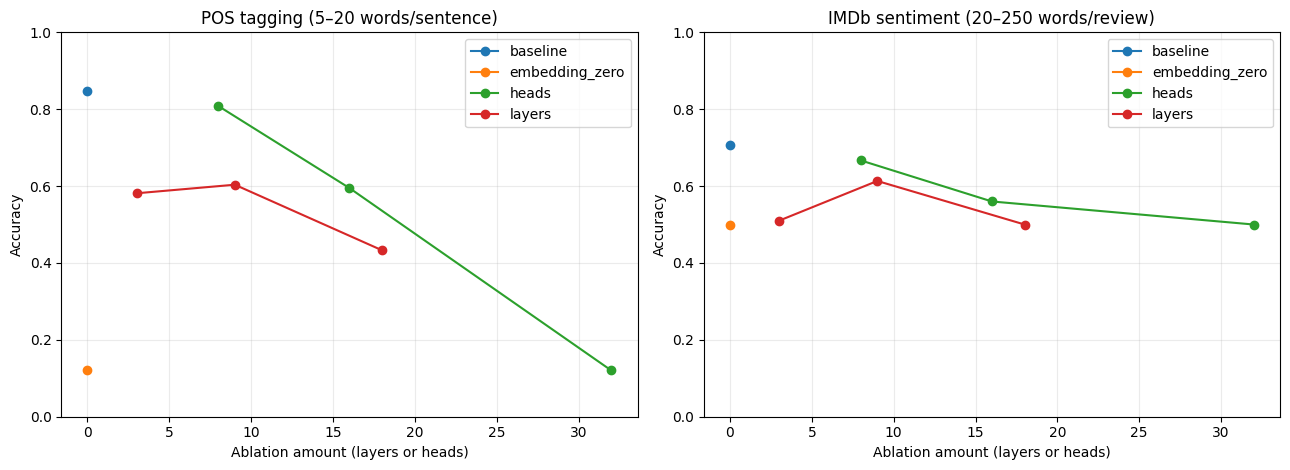

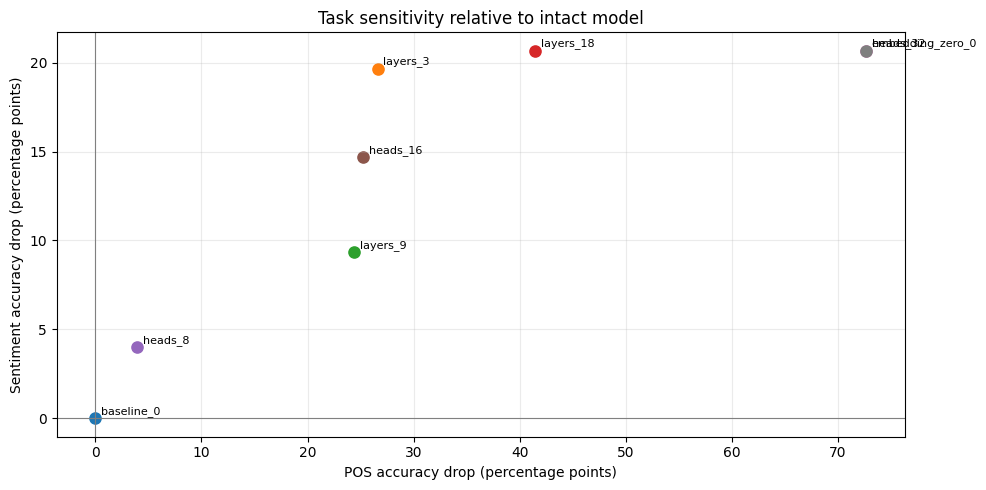

Saved plots: /kaggle/working/qwen3_ablation_accuracy.png /kaggle/working/qwen3_ablation_task_sensitivity.png


In [13]:
results_df = pd.read_csv(RESULTS_CSV)
pos_details = pd.read_csv(POS_DETAIL_CSV)
sent_details = pd.read_csv(SENT_DETAIL_CSV)
base_rows = results_df[results_df["condition"] == "baseline_0"]
if base_rows.empty: raise RuntimeError("Missing baseline_0; run the ablation cell first.")
base = base_rows.iloc[0]
summary = results_df.copy()
summary["pos_accuracy_drop_pp"] = 100 * (base["pos_accuracy"] - summary["pos_accuracy"])
summary["sentiment_accuracy_drop_pp"] = 100 * (base["sentiment_accuracy"] - summary["sentiment_accuracy"])
summary["pos_macro_f1_drop_pp"] = 100 * (base["pos_macro_f1"] - summary["pos_macro_f1"])
summary["sentiment_macro_f1_drop_pp"] = 100 * (base["sentiment_macro_f1"] - summary["sentiment_macro_f1"])
display(summary.round(3))
summary.to_csv(OUTPUT_DIR / "qwen3_ablation_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for kind, group in summary.groupby("ablation"):
    group = group.sort_values("amount")
    axes[0].plot(group["amount"], group["pos_accuracy"], marker="o", label=kind)
    axes[1].plot(group["amount"], group["sentiment_accuracy"], marker="o", label=kind)
axes[0].set_title("POS tagging (5–20 words/sentence)")
axes[1].set_title("IMDb sentiment (20–250 words/review)")
for ax in axes:
    ax.set_xlabel("Ablation amount (layers or heads)"); ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1); ax.grid(alpha=0.25); ax.legend()
plt.tight_layout()
path = OUTPUT_DIR / "qwen3_ablation_accuracy.png"
plt.savefig(path, dpi=180, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for _, r in summary.iterrows():
    ax.scatter(r["pos_accuracy_drop_pp"], r["sentiment_accuracy_drop_pp"], s=65)
    ax.annotate(r["condition"], (r["pos_accuracy_drop_pp"], r["sentiment_accuracy_drop_pp"]),
                xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.axhline(0, color="grey", linewidth=0.8); ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("POS accuracy drop (percentage points)"); ax.set_ylabel("Sentiment accuracy drop (percentage points)")
ax.set_title("Task sensitivity relative to intact model"); ax.grid(alpha=0.25)
plt.tight_layout()
path2 = OUTPUT_DIR / "qwen3_ablation_task_sensitivity.png"
plt.savefig(path2, dpi=180, bbox_inches="tight"); plt.show()
print("Saved plots:", path, path2)

## 11. Bootstrap confidence intervals

POS uses sentence-cluster bootstrap intervals (all tokens in a sampled sentence travel together). Sentiment intervals resample reviews. Intervals quantify evaluation-sample uncertainty; they do not account for random seed or model-checkpoint uncertainty.

,condition,task,accuracy,ci95_low,ci95_high,n
8,baseline_0,POS,0.8474,0.8351,0.8582,400
9,embedding_zero_0,POS,0.1210,0.1134,0.1278,400
10,heads_16,POS,0.5950,0.5757,0.6102,400
11,heads_32,POS,0.1203,0.1112,0.1300,400
12,heads_8,POS,0.8082,0.7954,0.8219,400
13,layers_18,POS,0.4329,0.4172,0.4495,400
14,layers_3,POS,0.5813,0.5659,0.5978,400
15,layers_9,POS,0.6036,0.5872,0.6226,400
0,baseline_0,sentiment,0.7067,0.6616,0.7617,300
1,embedding_zero_0,sentiment,0.5000,0.4449,0.5533,300


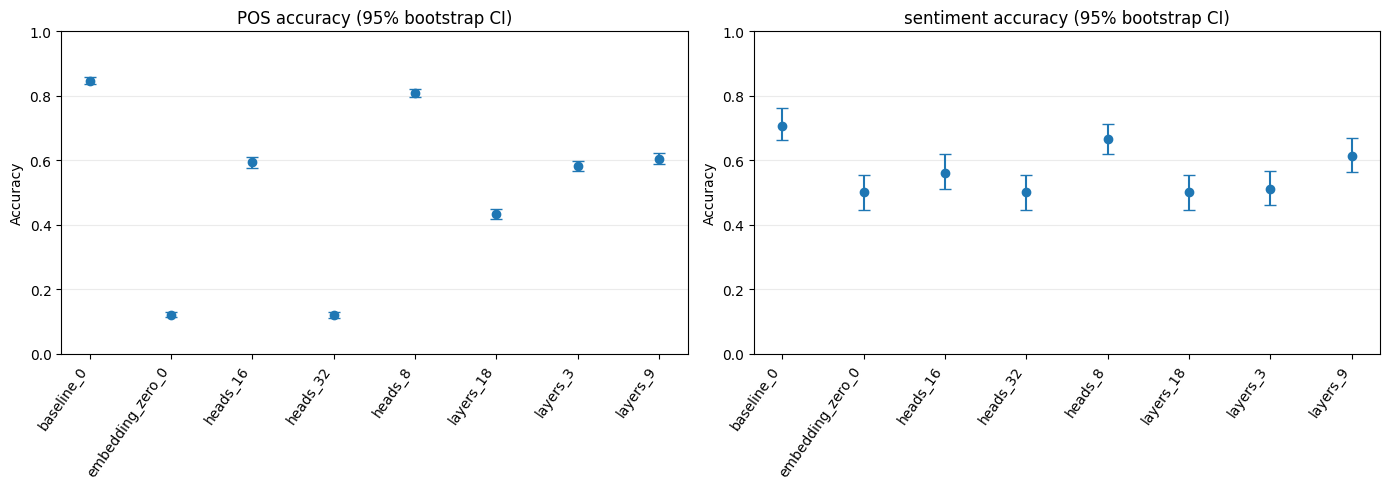

Saved CI table and plot: /kaggle/working/qwen3_ablation_confidence_intervals.png


In [14]:
def bootstrap_review_accuracy(gold, pred, n_boot=BOOTSTRAP_REPS, seed=SEED):
    rng = np.random.default_rng(seed); gold = np.asarray(gold); pred = np.asarray(pred)
    draws = np.empty(n_boot, dtype=np.float32); n = len(gold)
    for b in range(n_boot):
        ix = rng.integers(0, n, size=n); draws[b] = np.mean(gold[ix] == pred[ix])
    lo, hi = np.quantile(draws, [0.025, 0.975])
    return float(np.mean(gold == pred)), float(lo), float(hi)

def bootstrap_pos_clusters(frame, n_boot=BOOTSTRAP_REPS, seed=SEED):
    rng = np.random.default_rng(seed)
    clusters = {int(k): g[["gold", "predicted"]].astype(str).to_numpy()
                for k, g in frame.groupby("sentence_id")}
    keys = np.asarray(list(clusters), dtype=int)
    point = float(np.mean(frame["gold"].astype(str).to_numpy() == frame["predicted"].astype(str).to_numpy()))
    draws = np.empty(n_boot, dtype=np.float32)
    for b in range(n_boot):
        sampled = rng.choice(keys, size=len(keys), replace=True); correct = total = 0
        for k in sampled:
            pairs = clusters[int(k)]; correct += int(np.sum(pairs[:, 0] == pairs[:, 1])); total += len(pairs)
        draws[b] = correct / max(total, 1)
    lo, hi = np.quantile(draws, [0.025, 0.975])
    return point, float(lo), float(hi)

ci_rows = []
for condition, sub in sent_details.groupby("condition"):
    p, lo, hi = bootstrap_review_accuracy(sub["gold"], sub["predicted"])
    ci_rows.append({"condition": condition, "task": "sentiment", "accuracy": p, "ci95_low": lo, "ci95_high": hi, "n": len(sub)})
for condition, sub in pos_details.groupby("condition"):
    p, lo, hi = bootstrap_pos_clusters(sub)
    ci_rows.append({"condition": condition, "task": "POS", "accuracy": p, "ci95_low": lo, "ci95_high": hi, "n": sub["sentence_id"].nunique()})
ci_df = pd.DataFrame(ci_rows)
display(ci_df.sort_values(["task", "condition"]).round(4))
ci_df.to_csv(OUTPUT_DIR / "qwen3_ablation_confidence_intervals.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, task in zip(axes, ["POS", "sentiment"]):
    sub = ci_df[ci_df["task"] == task].sort_values("condition")
    x = np.arange(len(sub)); y = sub["accuracy"].to_numpy()
    err = np.vstack([y - sub["ci95_low"].to_numpy(), sub["ci95_high"].to_numpy() - y])
    ax.errorbar(x, y, yerr=err, fmt="o", capsize=4)
    ax.set_xticks(x); ax.set_xticklabels(sub["condition"], rotation=55, ha="right")
    ax.set_ylim(0, 1); ax.set_ylabel("Accuracy"); ax.set_title(f"{task} accuracy (95% bootstrap CI)"); ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
ci_plot = OUTPUT_DIR / "qwen3_ablation_confidence_intervals.png"
plt.savefig(ci_plot, dpi=180, bbox_inches="tight"); plt.show()
print("Saved CI table and plot:", ci_plot)

## 12. Sentiment by review length and report interpretation

This final analysis tests whether ablation has different effects for shorter and longer reviews within the selected range. The output CSV and graphs are suitable for building the assignment's tables; use the measured results rather than assuming a particular task fails first.

,condition,length_bucket,n,accuracy,macro_f1
0,baseline_0,121–250,232,0.7112,0.6965
1,baseline_0,20–60,11,0.7273,0.7179
2,baseline_0,61–120,57,0.6842,0.6794
3,embedding_zero_0,121–250,232,0.5086,0.3371
4,embedding_zero_0,20–60,11,0.4545,0.3125
5,embedding_zero_0,61–120,57,0.4737,0.3214
6,heads_16,121–250,232,0.5603,0.5587
7,heads_16,20–60,11,0.7273,0.7179
8,heads_16,61–120,57,0.5263,0.4959
9,heads_32,121–250,232,0.4914,0.3295


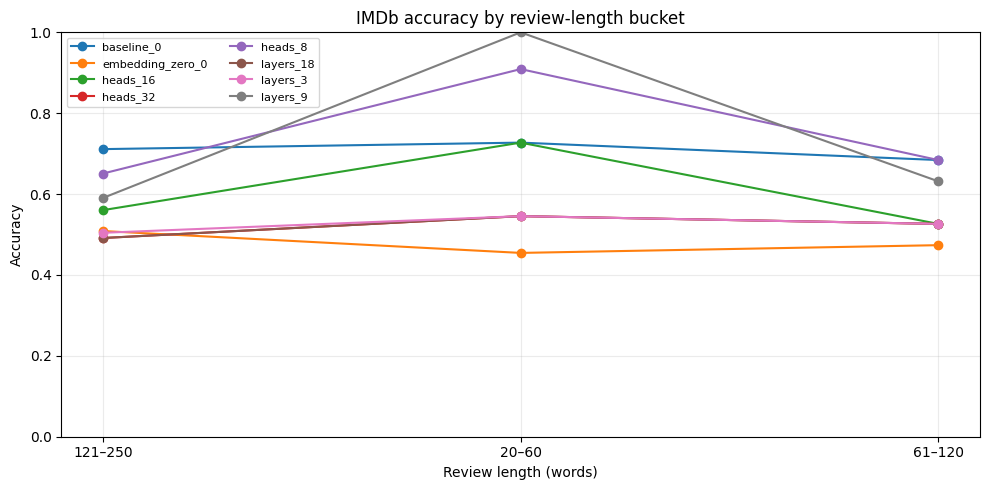


Export directory: /kaggle/working
qwen3_ablation_accuracy.png: 112,892 bytes
qwen3_ablation_confidence_intervals.csv: 1,230 bytes
qwen3_ablation_confidence_intervals.png: 92,566 bytes
qwen3_ablation_config.json: 793 bytes
qwen3_ablation_results.csv: 869 bytes
qwen3_ablation_summary.csv: 1,488 bytes
qwen3_ablation_task_sensitivity.png: 72,558 bytes
qwen3_pos_predictions.csv: 817,762 bytes
qwen3_sentiment_predictions.csv: 169,615 bytes
qwen3_sentiment_by_length.png: 120,048 bytes


In [15]:
length_rows = []
for (condition, bucket), sub in sent_details.groupby(["condition", "length_bucket"], observed=False):
    length_rows.append({"condition": condition, "length_bucket": bucket, "n": len(sub),
                        "accuracy": accuracy_score(sub["gold"], sub["predicted"]),
                        "macro_f1": f1_score(sub["gold"], sub["predicted"], average="macro", zero_division=0)})
length_df = pd.DataFrame(length_rows)
display(length_df.round(4))
fig, ax = plt.subplots(figsize=(10, 5))
for condition, sub in length_df.groupby("condition"):
    sub = sub.sort_values("length_bucket")
    ax.plot(sub["length_bucket"].astype(str), sub["accuracy"], marker="o", label=condition)
ax.set_xlabel("Review length (words)"); ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1)
ax.set_title("IMDb accuracy by review-length bucket"); ax.grid(alpha=0.25); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); lp = OUTPUT_DIR / "qwen3_sentiment_by_length.png"
plt.savefig(lp, dpi=180, bbox_inches="tight"); plt.show()

print("\nExport directory:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.glob("qwen3_ablation*")) + [OUTPUT_DIR / "qwen3_pos_predictions.csv", OUTPUT_DIR / "qwen3_sentiment_predictions.csv", lp]:
    if p.exists(): print(f"{p.name}: {p.stat().st_size:,} bytes")